In [2]:
!pip install sidetable
!conda install -c conda-forge --yes scienceplots

Channels:
 - conda-forge
 - defaults
Platform: osx-arm64
Solving environment: done

# All requested packages already installed.



In [3]:
import os
from configparser import ConfigParser
from matplotlib import pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import scienceplots
import seaborn as sns
import sidetable

In [4]:
plt.style.use('science')

In [5]:
os.getcwd()

'/Users/janik/source/urban-mobility-simulation/resources/scripts/simulation_analysis'

In [6]:
os.chdir("../../../")
os.getcwd()

'/Users/janik/source/urban-mobility-simulation'

In [7]:
from simulation.helper.time import SimulationTimeConverter

In [8]:
# Read args
parser = ConfigParser()
parser.read("resources/configurations/shared-charging.ini")

['resources/configurations/shared-charging.ini']

In [15]:
auction_tracking = pd.read_csv("data/output/tracking/auction.csv")

In [16]:
auction_tracking

,time,participant_id,location,_bids,_result
0,105,0,872664ca9ffffff,"[(3, 0.0, 0), (1, 0.6975306147362161, 0), (1, ...","(10, 0.0)"
1,120,1,872664c1effffff,"[(3, 0.0, 1), (1, 0.8198392054513413, 1), (1, ...","(10, 0.0)"
2,150,1,872664c16ffffff,"[(4, 0.0, 1), (1, 0.6975306147362161, 1), (1, ...","(10, 0.0)"
3,165,0,872664cacffffff,"[(3, 0.0, 0), (1, 0.6910444603158599, 0), (1, ...","(10, 0.0)"
4,210,0,872664cadffffff,"[(4, 0.0, 0), (1, 0.6975306147362161, 0), (1, ...","(10, 0.0)"
5,210,1,872664c13ffffff,"[(4, 0.0, 1), (1, 0.6975306147362161, 1), (1, ...","(10, 0.0)"
6,255,0,872664521ffffff,"[(9, 0.0, 0), (1, 3.757973379182092, 0)]","(10, 0.0)"
7,300,1,872664c1affffff,"[(9, 0.0, 1), (1, 0.010993177278058042, 1)]","(10, 0.0)"
8,495,0,872759343ffffff,"[(8, 0.0, 0), (1, 3.7559731620067476, 0), (1, ...","(10, 0.0)"


In [17]:
# rename time axis
auction_tracking['timestamp'] = pd.to_datetime(auction_tracking['time'].apply(SimulationTimeConverter.as_time), format="%H:%M:%S")

In [18]:
auction_tracking['_result.clearing_price'] = auction_tracking['_result'].apply(lambda x: eval(x)[1])
auction_tracking['_result.capacity'] = auction_tracking['_result'].apply(lambda x: eval(x)[0])

auction_tracking['_bids.total_capacity'] = auction_tracking['_bids'].apply(lambda x: sum([b[0] for b in eval(x)]))
auction_tracking['_bids.mean_bid'] = auction_tracking['_bids'].apply(lambda x: np.mean([b[1] for b in eval(x)]))

In [19]:
auction_tracking

,time,participant_id,location,_bids,_result,timestamp,_result.clearing_price,_result.capacity,_bids.total_capacity,_bids.mean_bid
0,105,0,872664ca9ffffff,"[(3, 0.0, 0), (1, 0.6975306147362161, 0), (1, ...","(10, 0.0)",1900-01-01 01:45:00,0.0,10,10,2.699643
1,120,1,872664c1effffff,"[(3, 0.0, 1), (1, 0.8198392054513413, 1), (1, ...","(10, 0.0)",1900-01-01 02:00:00,0.0,10,10,2.975955
2,150,1,872664c16ffffff,"[(4, 0.0, 1), (1, 0.6975306147362161, 1), (1, ...","(10, 0.0)",1900-01-01 02:30:00,0.0,10,10,1.861921
3,165,0,872664cacffffff,"[(3, 0.0, 0), (1, 0.6910444603158599, 0), (1, ...","(10, 0.0)",1900-01-01 02:45:00,0.0,10,10,1.243364
4,210,0,872664cadffffff,"[(4, 0.0, 0), (1, 0.6975306147362161, 0), (1, ...","(10, 0.0)",1900-01-01 03:30:00,0.0,10,10,1.861921
5,210,1,872664c13ffffff,"[(4, 0.0, 1), (1, 0.6975306147362161, 1), (1, ...","(10, 0.0)",1900-01-01 03:30:00,0.0,10,10,1.861921
6,255,0,872664521ffffff,"[(9, 0.0, 0), (1, 3.757973379182092, 0)]","(10, 0.0)",1900-01-01 04:15:00,0.0,10,10,1.878987
7,300,1,872664c1affffff,"[(9, 0.0, 1), (1, 0.010993177278058042, 1)]","(10, 0.0)",1900-01-01 05:00:00,0.0,10,10,0.005497
8,495,0,872759343ffffff,"[(8, 0.0, 0), (1, 3.7559731620067476, 0), (1, ...","(10, 0.0)",1900-01-01 08:15:00,0.0,10,10,2.918658


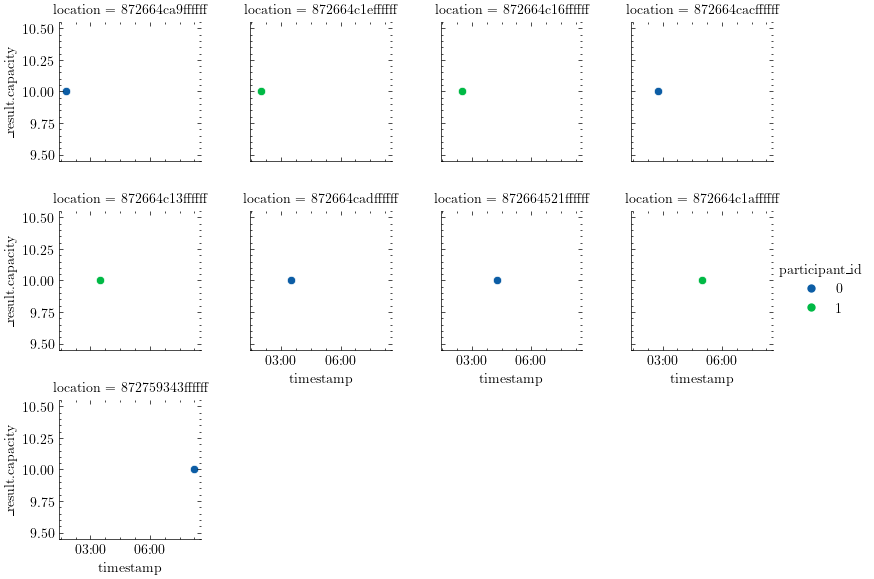

In [240]:
auction_tracking.sort_values(by=['time', 'location'], inplace=True)
g = sns.relplot(data=auction_tracking, x="timestamp", y="_result.capacity", hue="participant_id", col="location", col_wrap=4, kind="scatter", height=2)

axes = g.axes.flat

for a in axes:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=4))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

In [232]:
auction_tracking

,time,participant_id,location,_bids,_result,timestamp,_result.clearing_price,_result.capacity,_bids.total_capacity,_bids.mean_bid
0,105,0,872664ca9ffffff,"[(3, 0.0, 0), (1, 0.6975306147362161, 0), (1, ...","(10, 0.0)",1900-01-01 01:45:00,0.0,10,10,2.699643
1,120,1,872664c1effffff,"[(3, 0.0, 1), (1, 0.8198392054513413, 1), (1, ...","(10, 0.0)",1900-01-01 02:00:00,0.0,10,10,2.975955
2,150,1,872664c16ffffff,"[(4, 0.0, 1), (1, 0.6975306147362161, 1), (1, ...","(10, 0.0)",1900-01-01 02:30:00,0.0,10,10,1.861921
3,165,0,872664cacffffff,"[(3, 0.0, 0), (1, 0.6910444603158599, 0), (1, ...","(10, 0.0)",1900-01-01 02:45:00,0.0,10,10,1.243364
5,210,1,872664c13ffffff,"[(4, 0.0, 1), (1, 0.6975306147362161, 1), (1, ...","(10, 0.0)",1900-01-01 03:30:00,0.0,10,10,1.861921
4,210,0,872664cadffffff,"[(4, 0.0, 0), (1, 0.6975306147362161, 0), (1, ...","(10, 0.0)",1900-01-01 03:30:00,0.0,10,10,1.861921
6,255,0,872664521ffffff,"[(9, 0.0, 0), (1, 3.757973379182092, 0)]","(10, 0.0)",1900-01-01 04:15:00,0.0,10,10,1.878987
7,300,1,872664c1affffff,"[(9, 0.0, 1), (1, 0.010993177278058042, 1)]","(10, 0.0)",1900-01-01 05:00:00,0.0,10,10,0.005497
8,495,0,872759343ffffff,"[(8, 0.0, 0), (1, 3.7559731620067476, 0), (1, ...","(10, 0.0)",1900-01-01 08:15:00,0.0,10,10,2.918658


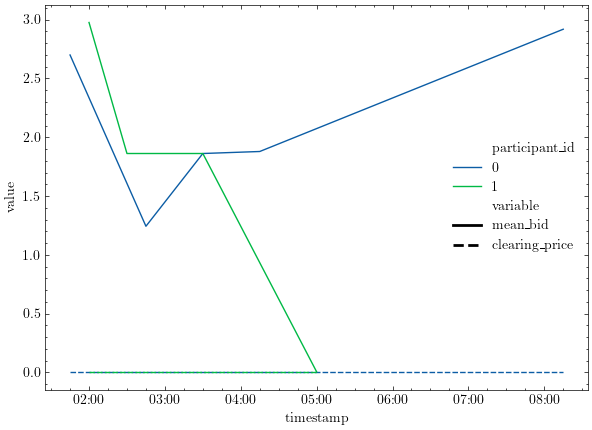

In [341]:
from matplotlib.lines import Line2D


fig, ax = plt.subplots(1,1, figsize=(7,5))

auction_tracking_long = auction_tracking.melt(id_vars=['timestamp', 'location', 'participant_id'], value_vars=['_result.clearing_price', '_bids.mean_bid'])
auction_tracking_long['variable'] = auction_tracking_long['variable'].astype('category')

sns.lineplot(data=auction_tracking_long, x="timestamp", y="value", hue="participant_id", style="variable", ax=ax)

handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([0], [0], color='black', lw=2, linestyle='solid'))
handles.append(Line2D([0], [0], color='black', lw=2, linestyle='dashed'))
labels.extend(['mean_bid', 'clearing_price'])

ax.legend(handles=handles, labels=labels)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=8))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

## Vehicles

In [220]:
vehicle_tracking = pd.read_csv("data/output/tracking/vehicles.csv")

In [221]:
vehicle_tracking['_state'].apply(lambda x: set(eval(x))).value_counts()

_state
{1, 2, 1003}                   938
{1, 2, 1003, 1001}             884
{1, 2, 3, 4, 5, 1003}          288
{1, 2, 3, 4, 5, 1001, 1003}    152
{1, 2, 3, 4, 1003}              82
{1, 2}                          78
{1, 2, 4, 1001, 1003}           69
{1, 2, 1003, 4}                 67
{1, 2, 3, 1003}                 62
{1, 2, 3, 1001, 1003}           53
{1, 2, 3, 4, 1001, 1003}        53
{1, 2, 1001}                    45
{1, 2, 3, 4, 5}                 24
{1, 2, 4, 5, 1003}              17
{1, 2, 3, 4}                    16
{1, 2, 3, 4, 5, 1001}           13
{1, 2, 4, 5, 1001, 1003}        13
{1}                             10
{1, 2, 3, 4, 1001}               7
{1, 2, 3, 1001}                  2
{1, 1001}                        2
{1, 1003}                        2
{1, 2, 3}                        1
Name: count, dtype: int64

In [222]:
RECHARGE_THRESHOLD = 25 # ATTENTION: This is an approximation, we use dynamic ones per base region

vehicle_tracking['fleet_average_SOC'] = vehicle_tracking['_current_state_of_charge'].apply(lambda x: np.mean(eval(x)))
vehicle_tracking['fleet_number_low_SOC'] = vehicle_tracking['_current_state_of_charge'].apply(lambda x: np.count_nonzero(np.array(eval(x))< RECHARGE_THRESHOLD))

In [223]:
# rename time axis
vehicle_tracking['time'] = pd.to_datetime(vehicle_tracking['time'].apply(SimulationTimeConverter.as_time), format="%H:%M:%S")

vehicle_tracking['timestamp'] = vehicle_tracking['time'].dt.strftime("%H:%M")

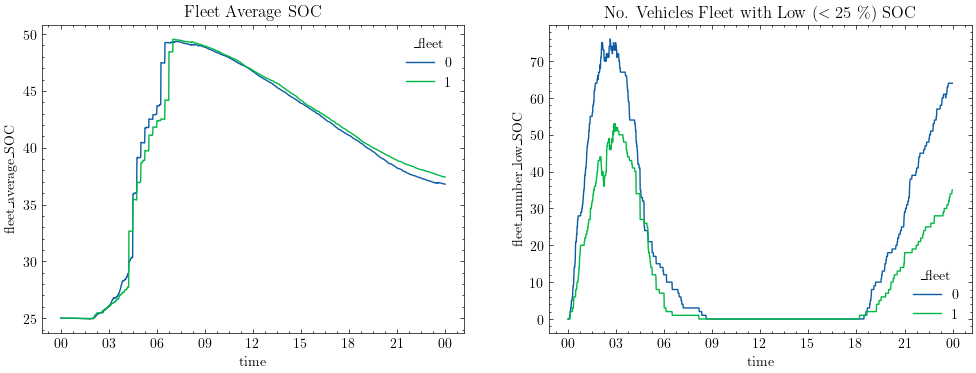

In [224]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (12, 4))

sns.lineplot(data=vehicle_tracking, x='time', y='fleet_average_SOC', hue='_fleet', ax = ax[0])
sns.lineplot(data=vehicle_tracking, x='time', y='fleet_number_low_SOC', hue='_fleet', ax = ax[1])

ax[0].set_title('Fleet Average SOC')
ax[1].set_title(f'No. Vehicles Fleet with Low ($< {RECHARGE_THRESHOLD}$ \%) SOC')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

In [225]:
INITIALIZED = 0
PARKING = 1
DRIVING = 2
RELOCATING = 3
CHARGING = 4
PRE_SERVICE = 5
ONLINE = 6  # When the driver is online
OFFLINE = 7  # When the driver is offline
SOME_STATE = 1002
RESERVED = 1001
MOVING_TO_PICK_UP_POS = 1003

In [226]:
vehicle_tracking['_state_PARKING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PARKING))

vehicle_tracking['_state_CHARGING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == CHARGING))

vehicle_tracking['_state_DRIVING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == DRIVING))

vehicle_tracking['_state_RELOCATING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RELOCATING))

vehicle_tracking['_state_PRE_SERVICE'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PRE_SERVICE))

vehicle_tracking['_state_MOVING_TO_PICK_UP_POS'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == MOVING_TO_PICK_UP_POS))

vehicle_tracking['_state_RESERVED'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RESERVED))

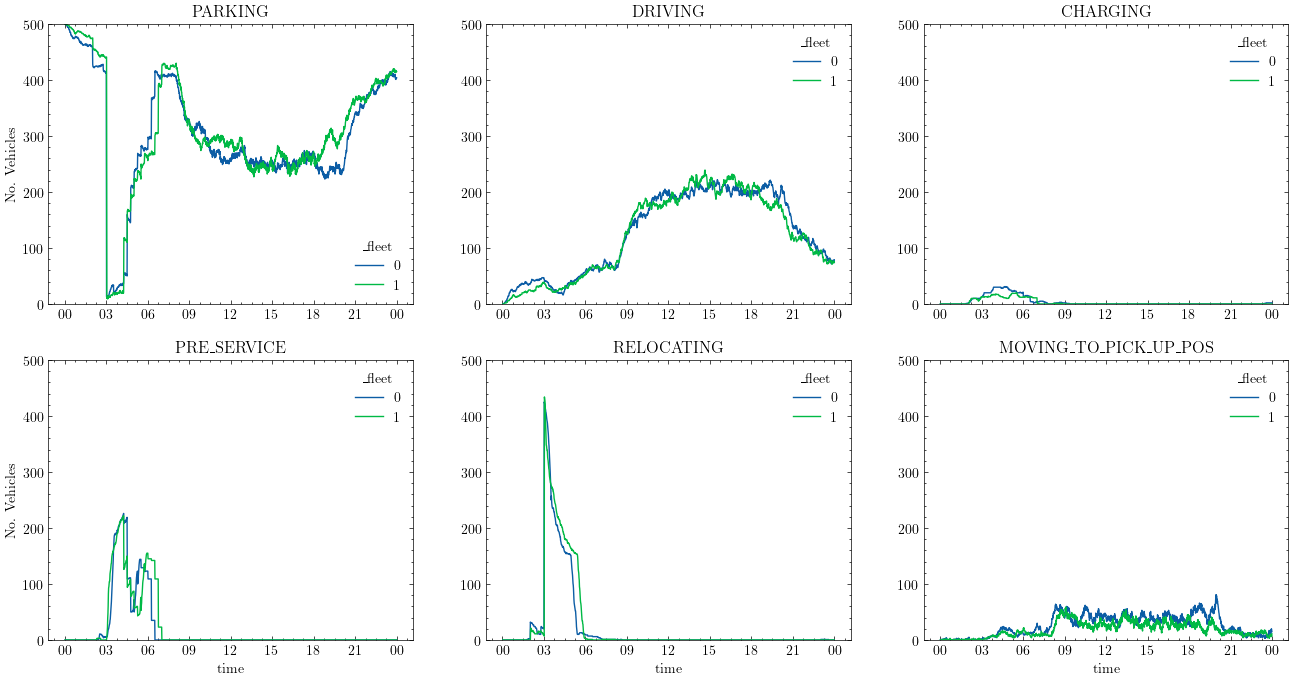

In [227]:
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(16, 8))
sns.lineplot(data=vehicle_tracking, x='time', y='_state_PARKING', hue='_fleet', ax=ax[0][0])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_DRIVING', hue='_fleet', ax=ax[0][1])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_CHARGING', hue='_fleet', ax=ax[0][2])

sns.lineplot(data=vehicle_tracking, x='time', y='_state_PRE_SERVICE', hue='_fleet', ax=ax[1][0])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_RELOCATING', hue='_fleet', ax=ax[1][1])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_MOVING_TO_PICK_UP_POS', hue='_fleet', ax=ax[1][2])

ax[0][0].set_title('PARKING')
ax[0][1].set_title('DRIVING')
ax[0][2].set_title('CHARGING')

ax[1][0].set_title('PRE_SERVICE')
ax[1][1].set_title('RELOCATING')
ax[1][2].set_title('MOVING_TO_PICK_UP_POS')


for aa in ax:
    for i, a in enumerate(aa):
        a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
        a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))


        a.set_ylabel('No. Vehicles')
        a.set_ylim(0, parser.getint("EXPERIMENT_MANAGEMENT", "N_CARS"))
        a.yaxis.label.set_visible(False) if i > 0 else None

for a in ax[0]:
    a.xaxis.label.set_visible(False)

## Charging Stations

In [241]:
charging_station_tracking = pd.read_csv("data/output/tracking/charging_stations.csv")

In [242]:
CHARGING_STATION_CAPACITY = parser.getint("CHARGING_INFRASTRUCTURE", "CHARGING_STATION_CAPACITY")

In [243]:
charging_station_tracking['utilization'] = charging_station_tracking['_plugs.count'] / CHARGING_STATION_CAPACITY

charging_station_tracking['system_wide_utilization'] = charging_station_tracking.groupby('time')['utilization'].transform('mean')

In [244]:
# rename time axis
charging_station_tracking['time'] = pd.to_datetime(charging_station_tracking['time'].apply(SimulationTimeConverter.as_time), format="%H:%M:%S")

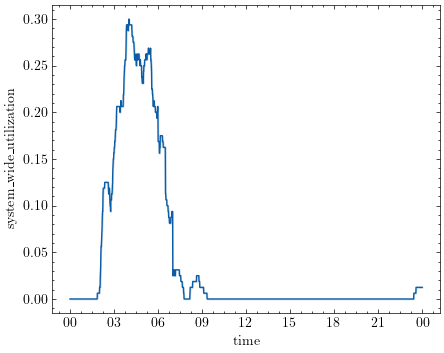

In [278]:
fig, ax = plt.subplots(1,1, figsize=(5,4))

sns.lineplot(data=charging_station_tracking, x='time', y='system_wide_utilization', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

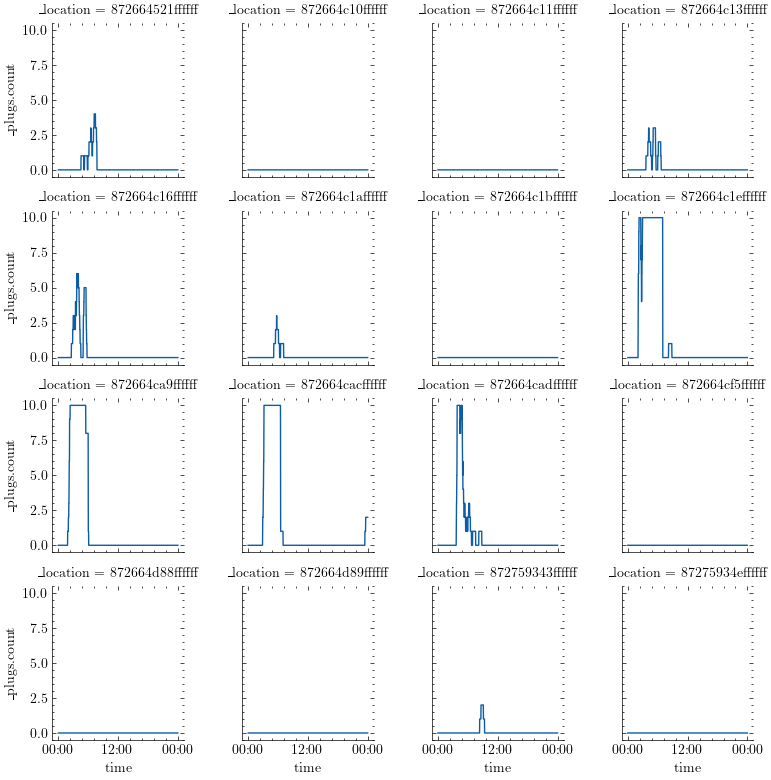

In [247]:
charging_station_tracking.sort_values(by=['time', '_location'], inplace=True)
g = sns.relplot(
    data=charging_station_tracking, x='time', y='_plugs.count', col='_location', kind='line', col_wrap=4, height=2)

axes = g.axes.flat

for a in axes:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=4))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

## Transactions

In [248]:
transactions_fleet_0 = pd.read_csv("data/output/transactions/fleet_0_transactions.csv")
transactions_fleet_1 = pd.read_csv("data/output/transactions/fleet_1_transactions.csv")

In [249]:
RESAMPLE_RATE = '1h'

In [271]:
transactions_fleet_0['timestamp'] = transactions_fleet_0['time_end'].apply(SimulationTimeConverter.as_time)
transactions_fleet_0['timestamp'] = pd.to_datetime(transactions_fleet_0['timestamp'], format="%H:%M:%S")
transactions_fleet_0_resampled = transactions_fleet_0.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_1['timestamp'] = transactions_fleet_1['time_end'].apply(SimulationTimeConverter.as_time)
transactions_fleet_1['timestamp'] = pd.to_datetime(transactions_fleet_1['timestamp'], format="%H:%M:%S")
transactions_fleet_1_resampled = transactions_fleet_1.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

In [272]:
# normalize
transactions_fleet_0_resampled = transactions_fleet_0_resampled.div(transactions_fleet_0_resampled.sum(axis=1), axis=0)

transactions_fleet_1_resampled = transactions_fleet_1_resampled.div(transactions_fleet_1_resampled.sum(axis=1), axis=0)

# rename time axis
transactions_fleet_0_resampled['timestamp'] = transactions_fleet_0_resampled.index.strftime("%H:%M")
transactions_fleet_0_resampled.set_index('timestamp', inplace=True)

transactions_fleet_1_resampled['timestamp'] = transactions_fleet_1_resampled.index.strftime("%H:%M")
transactions_fleet_1_resampled.set_index('timestamp', inplace=True)

In [273]:
transactions_fleet_0_resampled

state                    
state     Fulfilled    MISSED   REFUSED
timestamp                              
00:00      0.290323       NaN  0.709677
01:00      0.533333       NaN  0.466667
02:00      0.571429       NaN  0.428571
03:00      0.596774  0.241935  0.161290
04:00      0.442857  0.171429  0.385714
05:00      0.436782  0.160920  0.402299
06:00      0.494737  0.105263  0.400000
07:00      0.622449  0.010204  0.367347
08:00      0.560209       NaN  0.439791
09:00      0.665605  0.006369  0.328025
10:00      0.595870  0.008850  0.395280
11:00      0.665698  0.020349  0.313953
12:00      0.575893  0.093750  0.330357
13:00      0.610209  0.053364  0.336427
14:00      0.604396  0.096703  0.298901
15:00      0.570455  0.140909  0.288636
16:00      0.626327  0.046709  0.326964
17:00      0.640974  0.089249  0.269777
18:00      0.622172  0.088235  0.289593
19:00      0.622857  0.080000  0.297143
20:00      0.700809  0.118598  0.180593
21:00      0.633803  0.144366  0.221831
22:00      0.616034  0.080169  0.303797
23:00      0.498084  0.264368  0.237548

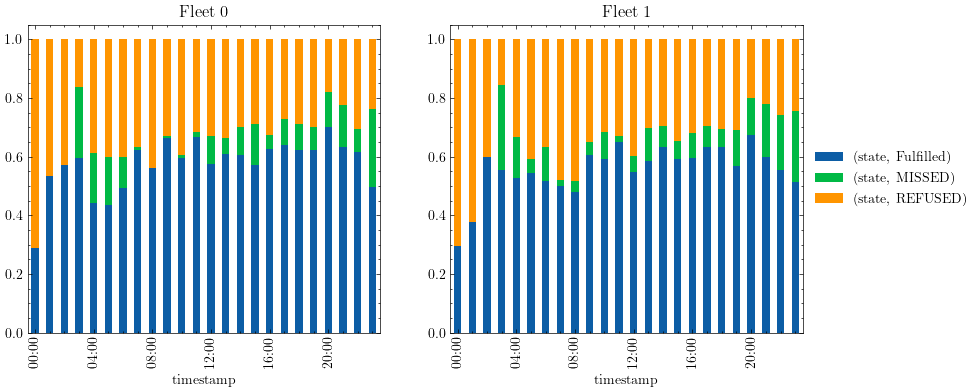

In [274]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

transactions_fleet_0_resampled.plot(kind = 'bar', stacked=True, ax=ax[0], legend=False)
transactions_fleet_1_resampled.plot(kind = 'bar', stacked=True, ax=ax[1], legend=True)

ax[1].legend(loc='center left', bbox_to_anchor=(1.0, 0.5))

ax[0].set_title('Fleet 0')
ax[1].set_title('Fleet 1')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=8))
    # a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

(0.0, 1.0)

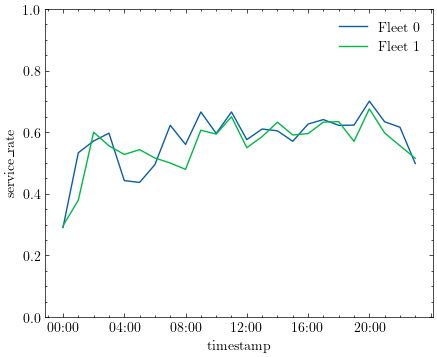

In [277]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5, 4))

transactions_fleet_0_resampled['service_rate'] = transactions_fleet_0_resampled[('state', 'Fulfilled')]
transactions_fleet_1_resampled['service_rate'] = transactions_fleet_1_resampled[('state', 'Fulfilled')]

# service_rate_mean = transactions_fleet_0_resampled.reset_index()[['timestamp', 'service_rate']].join(transactions_fleet_1_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')

sns.lineplot(data=transactions_fleet_0_resampled, x = transactions_fleet_0_resampled.index, y = 'service_rate', label='Fleet 0', ax=ax)
sns.lineplot(data=transactions_fleet_1_resampled, x = transactions_fleet_1_resampled.index, y = 'service_rate', label='Fleet 1', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
# ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

ax.set_ylim(0, 1.0)

### Vehilce Distance Travelled: Service vs. Operations

In [279]:
vehicle_tracking['fleet_vdt'] = vehicle_tracking['_vdt'].apply(lambda x: sum(eval(x)))

In [280]:
service_vdt_fleet_0 = transactions_fleet_0[transactions_fleet_0['state'] == 'Fulfilled'].resample(RESAMPLE_RATE, on = 'timestamp').agg({'distance': 'sum'})
service_vdt_fleet_1 = transactions_fleet_1[transactions_fleet_1['state'] == 'Fulfilled'].resample(RESAMPLE_RATE, on = 'timestamp').agg({'distance': 'sum'})

In [281]:
service_vdt_fleet_0['cumsum'] = service_vdt_fleet_0.cumsum()
service_vdt_fleet_1['cumsum'] = service_vdt_fleet_1.cumsum()

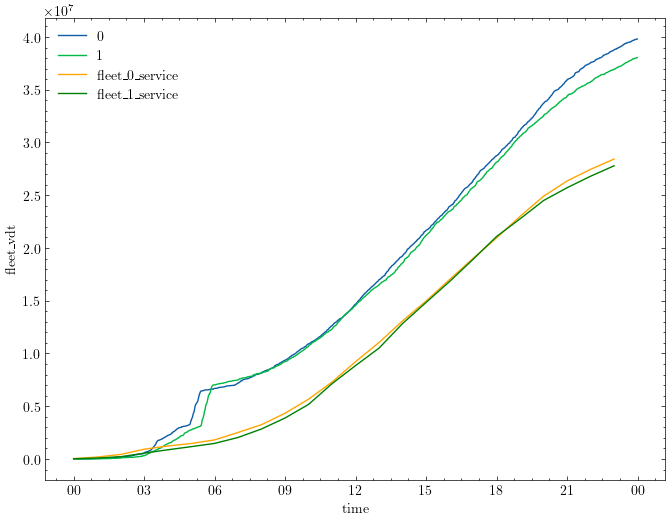

In [287]:
fig, ax = plt.subplots(1,1, figsize=(8, 6))

sns.lineplot(data=vehicle_tracking, x='time', y='fleet_vdt', hue='_fleet', ax=ax)
sns.lineplot(data=service_vdt_fleet_0, x='timestamp', y='cumsum', color='orange', label='fleet_0_service', ax=ax)
sns.lineplot(data=service_vdt_fleet_1, x='timestamp', y='cumsum', color='green', label='fleet_1_service', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

In [288]:
# share of operations VDT (excl customer serving)
hourly_vdt = vehicle_tracking.groupby('_fleet').resample(RESAMPLE_RATE, on = 'time').agg({'fleet_vdt': 'max'}).unstack(level=0).rename(columns={0: 'fleet_0_vdt_cumsum', 1: 'fleet_1_vdt_cumsum'}).droplevel(0, axis=1)

In [289]:
hourly_vdt = hourly_vdt.join(service_vdt_fleet_0)

hourly_vdt = hourly_vdt.join(service_vdt_fleet_1, rsuffix='_service_fleet_1')

hourly_vdt.rename(columns={'distance': 'distance_service_fleet_0', 'cumsum': 'cumsum_service_fleet_0'}, inplace=True)

hourly_vdt['fleet_0_ratio_of_empty_vdt'] = (hourly_vdt['fleet_0_vdt_cumsum'] - hourly_vdt['cumsum_service_fleet_0']) / hourly_vdt['fleet_0_vdt_cumsum']

hourly_vdt['fleet_1_ratio_of_empty_vdt'] = (hourly_vdt['fleet_1_vdt_cumsum'] - hourly_vdt['cumsum_service_fleet_1']) / hourly_vdt['fleet_1_vdt_cumsum']

In [290]:
hourly_vdt['fleet_0_vdt'] = hourly_vdt['fleet_0_vdt_cumsum'].diff().fillna(hourly_vdt['fleet_0_vdt_cumsum'].iloc[0])

hourly_vdt['fleet_1_vdt'] = hourly_vdt['fleet_1_vdt_cumsum'].diff().fillna(hourly_vdt['fleet_1_vdt_cumsum'].iloc[0])


In [291]:
hourly_vdt['fleet_0_ratio_of_empty_vdt'] = (hourly_vdt['fleet_0_vdt'] - hourly_vdt['distance_service_fleet_0']) / hourly_vdt['fleet_0_vdt']

hourly_vdt['fleet_1_ratio_of_empty_vdt'] = (hourly_vdt['fleet_1_vdt'] - hourly_vdt['distance_service_fleet_1']) / hourly_vdt['fleet_1_vdt']

In [292]:
hourly_vdt

,fleet_0_vdt_cumsum,fleet_1_vdt_cumsum,distance_service_fleet_0,cumsum_service_fleet_0,distance_service_fleet_1,cumsum_service_fleet_1,fleet_0_ratio_of_empty_vdt,fleet_1_ratio_of_empty_vdt,fleet_0_vdt,fleet_1_vdt
time,,,,,,,,,,
1900-01-01 00:00:00,4.599360e+04,2.550844e+04,3.683104e+04,3.683104e+04,2.144630e+04,2.144630e+04,0.199214,0.159247,4.599360e+04,2.550844e+04
1900-01-01 01:00:00,2.031360e+05,8.263431e+04,1.458067e+05,1.826377e+05,6.848458e+04,8.993088e+04,0.072137,-0.198837,1.571424e+05,5.712587e+04
1900-01-01 02:00:00,5.199759e+05,3.063108e+05,2.460207e+05,4.286584e+05,1.221690e+05,2.120998e+05,0.223517,0.453814,3.168399e+05,2.236765e+05
1900-01-01 03:00:00,2.199126e+06,1.433788e+06,4.949806e+05,9.236390e+05,3.383032e+05,5.504031e+05,0.705220,0.699947,1.679150e+06,1.127478e+06
1900-01-01 04:00:00,3.515314e+06,2.732422e+06,3.038467e+05,1.227486e+06,3.192552e+05,8.696582e+05,0.769146,0.754161,1.316188e+06,1.298634e+06
1900-01-01 05:00:00,6.684136e+06,7.025652e+06,2.390346e+05,1.466520e+06,2.978041e+05,1.167462e+06,0.924567,0.930634,3.168822e+06,4.293229e+06
1900-01-01 06:00:00,7.192352e+06,7.501614e+06,3.408954e+05,1.807416e+06,3.087444e+05,1.476207e+06,0.329231,0.351325,5.082161e+05,4.759618e+05
1900-01-01 07:00:00,8.142477e+06,8.143519e+06,7.100952e+05,2.517511e+06,5.636881e+05,2.039895e+06,0.252630,0.121852,9.501252e+05,6.419055e+05
1900-01-01 08:00:00,9.348088e+06,9.225360e+06,7.362106e+05,3.253721e+06,8.076389e+05,2.847534e+06,0.389346,0.253459,1.205611e+06,1.081841e+06


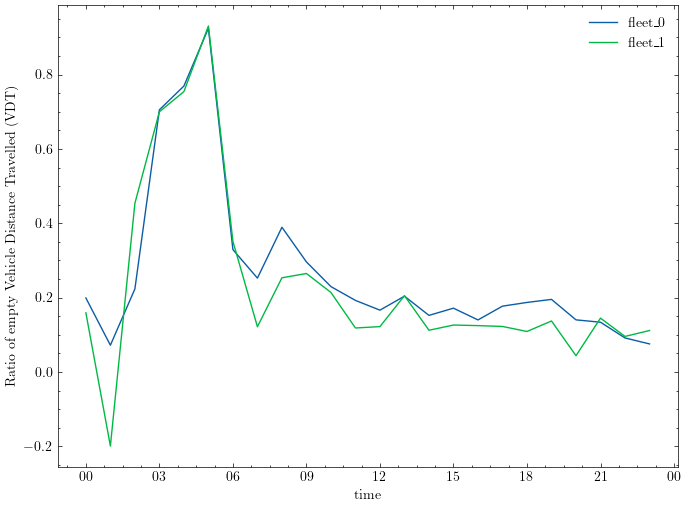

In [295]:
fig, ax = plt.subplots(1,1, figsize=(8, 6))

sns.lineplot(data=hourly_vdt, x='time', y='fleet_0_ratio_of_empty_vdt', label='fleet_0', ax=ax)
sns.lineplot(data=hourly_vdt, x='time', y='fleet_1_ratio_of_empty_vdt', label='fleet_1', ax=ax)

ax.set_ylabel('Ratio of empty Vehicle Distance Travelled (VDT)')

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

## Service Tasks

In [9]:
task_transactions_fleet_0 = pd.read_csv("data/output/transactions/fleet_0_task_transactions.csv")

task_transactions_fleet_1 = pd.read_csv("data/output/transactions/fleet_1_task_transactions.csv")

In [10]:
task_transactions_fleet_0['timestamp'] = task_transactions_fleet_0['start_time'].apply(SimulationTimeConverter.as_time)
task_transactions_fleet_0['timestamp'] = pd.to_datetime(task_transactions_fleet_0['timestamp'], format="%H:%M:%S")

task_transactions_fleet_1['timestamp'] = task_transactions_fleet_1['start_time'].apply(SimulationTimeConverter.as_time)
task_transactions_fleet_1['timestamp'] = pd.to_datetime(task_transactions_fleet_1['timestamp'], format="%H:%M:%S")

task_transactions_fleet_0['duration'] = task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['start_time']

task_transactions_fleet_1['duration'] = task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['start_time']

!! probably we should sanity-check why duration < waiting_time + charging_duration

In [11]:
task_transactions_fleet_0

,start_time,end_time,vehicle,state,fleet,charging_station,waiting_time,charging_duration,kWh_charged,timestamp,duration
0,106,145.966346,6,TaskState.FINISHED,0,872664ca9ffffff,7.132854,33.099201,27.582667,1900-01-01 01:46:00,39.966346
1,120,152.700020,162,TaskState.FINISHED,0,872664ca9ffffff,13.311777,31.011797,25.843164,1900-01-01 02:00:00,32.700020
2,113,159.740067,2,TaskState.FINISHED,0,872664ca9ffffff,8.724503,33.464570,27.887142,1900-01-01 01:53:00,46.740067
3,120,160.963056,34,TaskState.FINISHED,0,872664ca9ffffff,5.003094,30.966151,25.805126,1900-01-01 02:00:00,40.963056
4,120,161.628772,249,TaskState.FINISHED,0,872664ca9ffffff,4.022962,30.651734,25.543112,1900-01-01 02:00:00,41.628772
...,...,...,...,...,...,...,...,...,...,...,...
497,334,527.746884,89,TaskState.FINISHED,0,872664cadffffff,3.941628,36.688511,30.573760,1900-01-01 05:34:00,193.746884
498,496,546.162861,184,TaskState.FINISHED,0,872759343ffffff,8.765405,44.928266,37.440222,1900-01-01 08:16:00,50.162861
499,510,560.284281,11,TaskState.FINISHED,0,872759343ffffff,7.727767,43.012048,35.843373,1900-01-01 08:30:00,50.284281
500,1380,1440.000000,2,TaskState.EXECUTING_CHARGING,0,872664cacffffff,-24.680631,35.319369,29.432807,1900-01-01 23:00:00,60.000000


In [12]:
display(task_transactions_fleet_0.value_counts(subset=['state']))
display(task_transactions_fleet_1.value_counts(subset=['state']))

state                       
TaskState.FINISHED              500
TaskState.EXECUTING_CHARGING      2
Name: count, dtype: int64

state             
TaskState.FINISHED    500
Name: count, dtype: int64

<Axes: xlabel='charging_duration', ylabel='kWh_charged'>

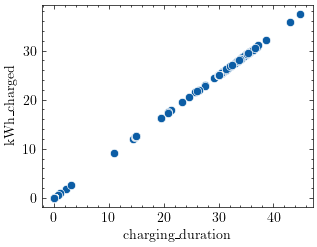

In [300]:
# check linearity
sns.scatterplot(data=task_transactions_fleet_0, x='charging_duration', y='kWh_charged')

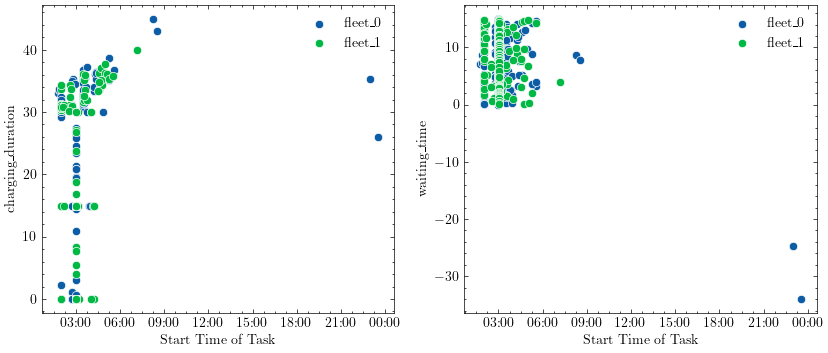

In [301]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

sns.scatterplot(data=task_transactions_fleet_0, x='timestamp', y='charging_duration', label='fleet_0', ax=ax[0])
sns.scatterplot(data=task_transactions_fleet_1, x='timestamp', y='charging_duration', label='fleet_1', ax=ax[0])

sns.scatterplot(data=task_transactions_fleet_0, x='timestamp', y='waiting_time', label='fleet_0', ax=ax[1])
sns.scatterplot(data=task_transactions_fleet_1, x='timestamp', y='waiting_time', label='fleet_1', ax=ax[1])

for a in ax:
    a.set_xlabel('Start Time of Task')
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

In [302]:
hourly_tasks = pd.merge(
    task_transactions_fleet_0.resample('h', on='timestamp').agg({'fleet': 'count', 'waiting_time': 'mean', 'charging_duration': 'mean'}).rename(columns={'fleet': 'tasks_finished_fleet_0', 'waiting_time': 'avg_waiting_time_fleet_0', 'charging_duration': 'avg_charging_duration_fleet_0'}),
    task_transactions_fleet_1.resample('h', on='timestamp').agg({'fleet': 'count', 'waiting_time': 'mean', 'charging_duration': 'mean'}).rename(columns={'fleet': 'tasks_finished_fleet_1', 'waiting_time': 'avg_waiting_time_fleet_1', 'charging_duration': 'avg_charging_duration_fleet_1'}),
    how='outer',
    left_index=True,
    right_index=True
).fillna(0)

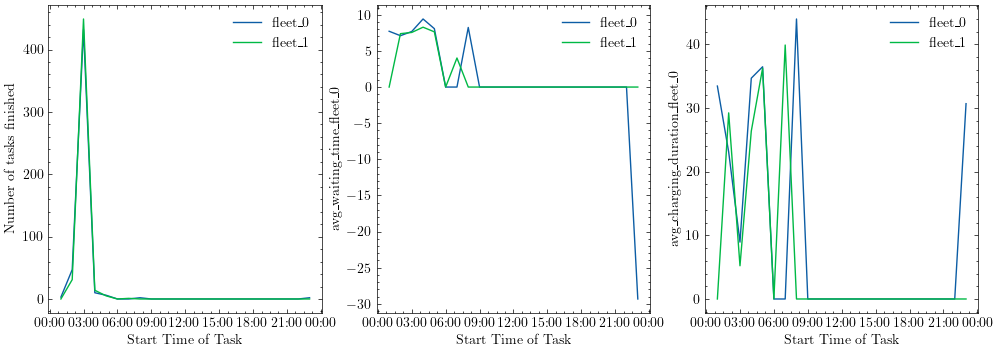

In [303]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(12, 4))

sns.lineplot(data=hourly_tasks, x='timestamp', y='tasks_finished_fleet_0', label='fleet_0', ax=ax[0])
sns.lineplot(data=hourly_tasks, x='timestamp', y='tasks_finished_fleet_1', label='fleet_1', ax=ax[0])

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_0', label='fleet_0', ax=ax[1])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_1', label='fleet_1', ax=ax[1])

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_charging_duration_fleet_0', label='fleet_0', ax=ax[2])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_charging_duration_fleet_1', label='fleet_1', ax=ax[2])

ax[0].set_ylabel("Number of tasks finished")

for a in ax:
    a.set_xlabel('Start Time of Task')
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

In [304]:
date_range = range(0,1440,15)

hourly_events_fleet_0 = pd.DataFrame({'time': date_range, 'events_ongoing_fleet_0': [((task_transactions_fleet_0['start_time'] <= i) & (task_transactions_fleet_0['end_time'] > i)).sum() for i in date_range]})
hourly_events_fleet_0.set_index('time', inplace=True)

hourly_events_fleet_1 = pd.DataFrame({'time': date_range, 'events_ongoing_fleet_1': [((task_transactions_fleet_1['start_time'] <= i) & (task_transactions_fleet_1['end_time'] > i)).sum() for i in date_range]})
hourly_events_fleet_1.set_index('time', inplace=True)

hourly_events_ongoing = pd.merge(
    hourly_events_fleet_0,
    hourly_events_fleet_1,
    how='outer',
    left_index=True,
    right_index=True
).fillna(0)

hourly_events_ongoing.reset_index(inplace=True)

In [305]:
hourly_events_ongoing['timestamp'] = hourly_events_ongoing['time'].apply(SimulationTimeConverter.as_time)
hourly_events_ongoing['timestamp'] = pd.to_datetime(hourly_events_ongoing['timestamp'], format="%H:%M:%S")

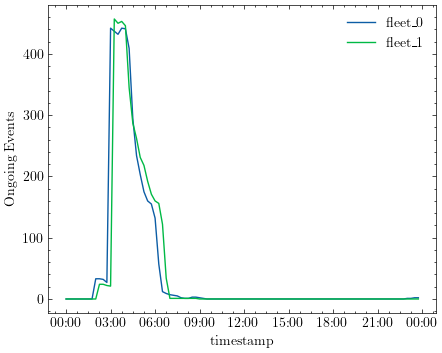

In [306]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5, 4))

sns.lineplot(data=hourly_events_ongoing, x='timestamp', y='events_ongoing_fleet_0', label='fleet_0', ax=ax)
sns.lineplot(data=hourly_events_ongoing, x='timestamp', y='events_ongoing_fleet_1', label='fleet_1', ax=ax)

ax.set_ylabel('Ongoing Events')

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))


In [24]:
task_transactions_fleet_0['timeslot'] = (task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['charging_duration']) - ((task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['charging_duration']) % 15)

task_transactions_fleet_1['timeslot'] = (task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['charging_duration']) - ((task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['charging_duration']) % 15)

In [25]:
tasks_incl_price = pd.concat(
    [task_transactions_fleet_0,task_transactions_fleet_1]
    ).merge(
        auction_tracking[['time', '_result.clearing_price']], 
        how='left', 
        left_on = 'timeslot', 
        right_on = "time"
        )

In [26]:
kWh_price = parser.getfloat("AUTONOMOUS_CAR", "CHARGING_COST_PER_KWH")

tasks_incl_price['charging_cost'] = tasks_incl_price['kWh_charged'] * kWh_price

In [31]:
tasks_incl_price

,start_time,end_time,vehicle,state,fleet,charging_station,waiting_time,charging_duration,kWh_charged,timestamp,duration,timeslot,time,_result.clearing_price,charging_cost
0,106,145.966346,6,TaskState.FINISHED,0,872664ca9ffffff,7.132854,33.099201,27.582667,1900-01-01 01:46:00,39.966346,105.0,105.0,0.0,11.860547
1,120,152.700020,162,TaskState.FINISHED,0,872664ca9ffffff,13.311777,31.011797,25.843164,1900-01-01 02:00:00,32.700020,120.0,120.0,0.0,11.112560
2,113,159.740067,2,TaskState.FINISHED,0,872664ca9ffffff,8.724503,33.464570,27.887142,1900-01-01 01:53:00,46.740067,120.0,120.0,0.0,11.991471
3,120,160.963056,34,TaskState.FINISHED,0,872664ca9ffffff,5.003094,30.966151,25.805126,1900-01-01 02:00:00,40.963056,120.0,120.0,0.0,11.096204
4,120,161.628772,249,TaskState.FINISHED,0,872664ca9ffffff,4.022962,30.651734,25.543112,1900-01-01 02:00:00,41.628772,120.0,120.0,0.0,10.983538
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1022,181,420.000000,873,TaskState.FINISHED,1,872664c1effffff,6.562003,0.000000,0.000000,1900-01-01 03:01:00,239.000000,420.0,NaN,NaN,0.000000
1023,181,420.000000,870,TaskState.FINISHED,1,872664c1effffff,5.867985,0.000000,0.000000,1900-01-01 03:01:00,239.000000,420.0,NaN,NaN,0.000000
1024,181,420.000000,881,TaskState.FINISHED,1,872664c1effffff,4.809207,0.000000,0.000000,1900-01-01 03:01:00,239.000000,420.0,NaN,NaN,0.000000
1025,301,427.851253,890,TaskState.FINISHED,1,872664c1affffff,14.838249,37.689502,31.407918,1900-01-01 05:01:00,126.851253,390.0,NaN,NaN,13.505405


In [39]:
hourly_costs = tasks_incl_price.groupby('fleet').resample('1h', on='timestamp').agg({'charging_cost': 'sum', '_result.clearing_price': 'sum'}).reset_index()
hourly_costs.rename(columns={'_result.clearing_price': 'reservation_cost'}, inplace=True)

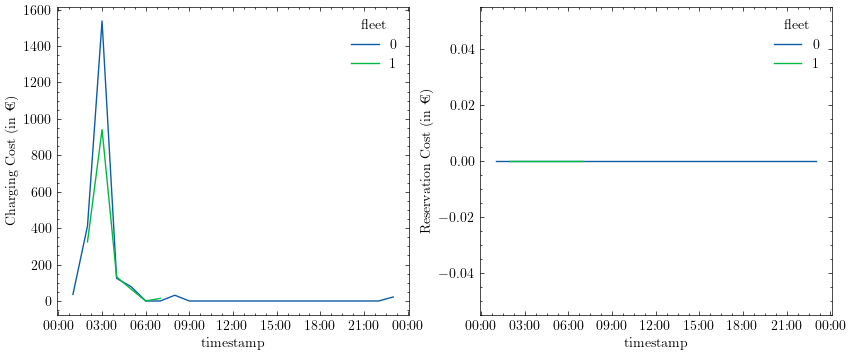

In [41]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

sns.lineplot(hourly_costs, x='timestamp', y='charging_cost', hue='fleet', ax=ax[0])
sns.lineplot(hourly_costs, x='timestamp', y='reservation_cost', hue='fleet', ax=ax[1])

ax[0].set_ylabel('Charging Cost (in €)')
ax[1].set_ylabel('Reservation Cost (in €)')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

### other stuff

<Axes: xlabel='waiting_time', ylabel='pick_up_time'>

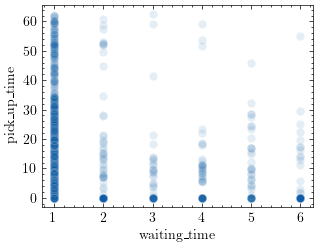

In [60]:
sns.scatterplot(transactions_fleet_0, x='waiting_time', y='pick_up_time', alpha=.1)

In [61]:
transactions_fleet_0['pick_up_time'].describe()

count    6618.000000
mean        5.894817
std         9.480927
min         0.000000
25%         0.000000
50%         2.184639
75%         7.826564
max        62.504271
Name: pick_up_time, dtype: float64